<a href="https://colab.research.google.com/github/moraortizs17/olist-ecommerce-eda/blob/main/Entrega_1_de_DataScience_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de Fricción Logística y Percepción del Cliente en E-Commerce
Red de distribución de Olist Brasil de 2016 a 2018

**Por:** Santiago Mora Ortiz

**Curso:** Datascience II



### Contexto y Abstracto
En los modelos de negocio basados en comercio electrónico y plataformas de marketplace, la experiencia poscompra define en gran medida la retención del comprador. Cuando un usuario califica una orden con 1 o 2 estrellas (cliente detractor), la causa rara vez responde a un solo factor: suele existir una combinación entre promesas logísticas rotas, costos desproporcionados de transporte y demoras operativas según la geografía.

Este proyecto examina de extremo a extremo las transacciones operativas de Olist, la plataforma de comercio electrónico líder en Brasil, conectando más de 98.000 pedidos reales a través de sus tablas de órdenes, logística, productos, clientes y reseñas, complementadas con datos de conversión cambiaria en tiempo real vía API. El propósito de esta primera fase exploratoria consiste en identificar con rigor empírico cuáles son las variables operativas que verdaderamente detonan la insatisfacción del cliente, limpiando inconsistencias de captura y sentando las bases analíticas para construir un modelo de Machine Learning en la entrega final.

### Audiencia Objetivo
El análisis está estructurado para presentar ante la Dirección de Operaciones y Logística, la Gerencia de Experiencia al Cliente (CX) y el equipo de Estrategia Comercial. El interés principal para estos tomadores de decisión radica en comprender dónde se generan los cuellos de botella del servicio para ajustar los algoritmos de estimación de entrega, negociar acuerdos de nivel de servicio (SLA) con transportistas y reducir la tasa de clientes detractores.

### Preguntas de Negocio e Hipótesis
A lo largo de la exploración se evalúan seis hipótesis concretas formuladas a partir de la dinámica operativa de la plataforma:

1. **Impacto del retraso:** El incumplimiento de la fecha de entrega prometida por la plataforma eleva exponencialmente las evaluaciones negativas, siendo el principal determinante de un cliente detractor.
2. **Fricción comercial del flete:** Un costo de envío desproporcionado respecto al valor comercial del artículo deteriora la percepción de compra y castiga la calificación final.
3. **Brechas territoriales:** La concentración geográfica de vendedores en el centro del país genera una penalización sistemática en los tiempos de tránsito y en la tasa de cumplimiento hacia estados periféricos.
4. **Restricciones físicas de carga:** Los productos voluminosos o pesados experimentan mayores tiempos de traslado debido a las restricciones de la paquetería estándar y la necesidad de transporte consolidado.
5. **Sensibilidad por línea de catálogo:** Categorías con mayor complejidad de instalación, dimensiones o fragilidad concentran mayores niveles de quejas que aquellas de consumo personal estandarizado.
6. **Saturación estacional de la red:** Los eventos de descuento masivo (como Black Friday) sobrecargan la capacidad instalada de los operadores postales, multiplicando la tasa de pedidos entregados con demora.

In [119]:
import os
import requests
import kagglehub
import pandas as pd
import numpy as np
from IPython.display import Image, display
import matplotlib.pyplot as plt
import seaborn as sns

**Explicación:** En esta parte se incluye la descarga de los datos de la base de datos, en este caso de Kaggle, el lugar donde se encuentra.

Como en este caso, se trata de un modelo relacional con diferentes tablas, traemos todas para hacer un merge de las mismas y aumentar la cantidad de variables disponibles.

In [120]:
!pip install -q kagglehub

print("Descargando tablas maestras de Olist desde Kaggle")
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

df_orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
df_items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
df_reviews = pd.read_csv(os.path.join(path, "olist_order_reviews_dataset.csv"))
df_products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))
df_customers = pd.read_csv(os.path.join(path, "olist_customers_dataset.csv"))

Descargando tablas maestras de Olist desde Kaggle
Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.


En este dataset queremos averiguar cómo afecta la logística del producto en la satisfacción del cliente, por lo cual me quiero enfocar solo en los productos delivered, en este caso miro si hay más opciones además de delivered para poderlos remover.

In [121]:
df_orders['order_status'].value_counts()

,count
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


Luego de ello, se procede a solo dejar el estado delivered ya que si un pedido nunca fue entregado, no hay manera de conocer la satisfacción del cliente y tiempo de entrega del paquete.

In [122]:
df_orders = df_orders[df_orders['order_status'] == 'delivered'].copy()

Ahora que quedó removido, quiero ver el modelo entidad relación para hacer un merge entre las tablas

In [123]:
url_esquema = "https://i.imgur.com/HRhd2Y0.png"
display(Image(url=url_esquema, width=700))

Ahora, hago una inspección de las tablas para identificar la PK y FK

In [124]:
archivos = {
    "orders": df_orders,
    "items": df_items,
    "reviews": df_reviews,
    "products": df_products,
    "customers": df_customers
}

for nombre, tabla in archivos.items():
    print(f"Tabla: {nombre} ({tabla.shape[0]:,} filas)")
    print(f"Columnas: {list(tabla.columns)}\n")

Tabla: orders (96,478 filas)
Columnas: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Tabla: items (112,650 filas)
Columnas: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Tabla: reviews (99,224 filas)
Columnas: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Tabla: products (32,951 filas)
Columnas: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Tabla: customers (99,441 filas)
Columnas: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']



Hago el merge con la información anterior

In [125]:
df_merged = pd.merge(df_orders, df_items[['order_id', 'product_id', 'price', 'freight_value']], on='order_id', how='inner')
df_merged = pd.merge(df_merged, df_products[['product_id', 'product_category_name', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']], on='product_id', how='left')
df_merged = pd.merge(df_merged, df_customers[['customer_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
df_merged = pd.merge(df_merged, df_reviews[['order_id', 'review_score']], on='order_id', how='inner')
df_merged = df_merged.drop_duplicates(subset=['order_id', 'product_id'])

In [126]:
df_sellers = pd.read_csv(os.path.join(path, "olist_sellers_dataset.csv"))

despachos_origen = pd.merge(df_items[['order_id', 'seller_id']], df_sellers[['seller_id', 'seller_state']], on='seller_id', how='left')

Teniendo en cuenta que el dataset viene de Brasil, todos los precios se encuentran en Reales Brasileños, por lo que en este caso le pedí a la IA de Gemini que podía hacer y aquella me recomendó pasarla a dólares a través de una API Key de exchangerate-api.com para que realice la tasa de cambio. Asimismo, en caso tal de que la API Key no funcione, se tiene predetermidana una tasa de cambio del 0.20

In [127]:
api_url = "https://open.er-api.com/v6/latest/BRL"
response = requests.get(api_url)
tasa_usd = response.json().get("rates", {}).get("USD", 0.20) if response.status_code == 200 else 0.20

if response:
    print(f"Tasa de cambio USD/BRL obtenida exitosamente: {tasa_usd}")
else:
    print("Error al consultar la API, usando tasa de respaldo (0.20)")

df_merged['precio_usd'] = (df_merged['price'] * tasa_usd).round(2)
df_merged['flete_usd'] = (df_merged['freight_value'] * tasa_usd).round(2)

Tasa de cambio USD/BRL obtenida exitosamente: 0.17654


Guardo el archivo local como olist_consolidado_crudo.csv

In [128]:

df_merged.to_csv("olist_consolidado_crudo.csv", index=False)
df_raw = df_merged.copy()

print(f"Dataset crudo consolidado: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas.")

Dataset crudo consolidado: 99,503 filas y 21 columnas.


In [129]:
df_raw.describe()

,price,freight_value,product_weight_g,product_length_cm,product_height_cm,product_width_cm,review_score,precio_usd,flete_usd
count,99503.00000,99503.000000,99487.000000,99487.000000,99487.000000,99487.000000,99503.000000,99503.000000,99503.000000
mean,123.58672,20.063866,2083.509061,30.059676,16.362670,23.022495,4.126579,21.817942,3.541974
std,186.30726,15.770406,3736.498679,16.055411,13.268845,11.723641,1.310074,32.890707,2.784210
min,0.85000,0.000000,0.000000,7.000000,2.000000,6.000000,1.000000,0.150000,0.000000
25%,40.00000,13.130000,300.000000,18.000000,8.000000,15.000000,4.000000,7.060000,2.320000
50%,78.00000,16.320000,683.000000,25.000000,13.000000,20.000000,5.000000,13.770000,2.880000
75%,139.00000,21.190000,1800.000000,38.000000,20.000000,30.000000,5.000000,24.540000,3.740000
max,6735.00000,409.680000,40425.000000,105.000000,105.000000,118.000000,5.000000,1189.000000,72.320000


#**Data Understanding**

Revisamos la dimensiones reales, vemos una muestra de los datos y el tipo de dato por columna

In [130]:
print(f"Total de filas: {df_raw.shape[0]:,} | Total de columnas: {df_raw.shape[1]}")

display(df_raw.head())
df_raw.info()

Total de filas: 99,503 | Total de columnas: 21


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,product_id,price,...,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,customer_city,customer_state,review_score,precio_usd,flete_usd
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,87285b34884572647811a353c7ac498a,29.99,...,utilidades_domesticas,500.0,19.0,8.0,13.0,sao paulo,SP,4,5.29,1.54
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,595fac2a385ac33a80bd5114aec74eb8,118.70,...,perfumaria,400.0,19.0,13.0,19.0,barreiras,BA,4,20.96,4.02
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,aa4383b373c6aca5d8797843e5594415,159.90,...,automotivo,420.0,24.0,19.0,21.0,vianopolis,GO,5,28.23,3.39
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,d0b61bfb1de832b15ba9d266ca96e5b0,45.00,...,pet_shop,450.0,30.0,10.0,20.0,sao goncalo do amarante,RN,5,7.94,4.80
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,65266b2da20d04dbe00c5c2d3bb7859e,19.90,...,papelaria,250.0,51.0,15.0,15.0,santo andre,SP,5,3.51,1.54


<class 'pandas.core.frame.DataFrame'>
Index: 99503 entries, 0 to 110012
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   order_id                       99503 non-null  object 
 1   customer_id                    99503 non-null  object 
 2   order_status                   99503 non-null  object 
 3   order_purchase_timestamp       99503 non-null  object 
 4   order_approved_at              99489 non-null  object 
 5   order_delivered_carrier_date   99501 non-null  object 
 6   order_delivered_customer_date  99495 non-null  object 
 7   order_estimated_delivery_date  99503 non-null  object 
 8   product_id                     99503 non-null  object 
 9   price                          99503 non-null  float64
 10  freight_value                  99503 non-null  float64
 11  product_category_name          98112 non-null  object 
 12  product_weight_g               99487 non-null  flo

Me aseguro que todos los pedidos hayan sido entregados

In [131]:
df_raw['order_status'].value_counts()

,count
order_status,
delivered,99503


Calculo la cantidad de valores nulos con su porcentaje

In [132]:
nulos = df_raw.isnull().sum()
pct_nulos = (nulos / len(df_raw)) * 100

tabla_calidad = pd.DataFrame({'Faltantes': nulos, 'Porcentaje (%)': pct_nulos.round(2)})
tabla_calidad[tabla_calidad['Faltantes'] > 0].sort_values(by='Faltantes', ascending=False)

,Faltantes,Porcentaje (%)
product_category_name,1391,1.40
product_height_cm,16,0.02
product_length_cm,16,0.02
product_weight_g,16,0.02
product_width_cm,16,0.02
order_approved_at,14,0.01
order_delivered_customer_date,8,0.01
order_delivered_carrier_date,2,0.00


Como se había visualizado anteriormente, algunas coumnas no estaban en formato de fecha, por lo que se hace el respectivo cambio.
Adicionalmente, se eliminan 8 de los registros nulos que son los que no tienen fecha de entrega y que hacen imposible determinar si ese factor influye en la satisfacción del cliente.

In [133]:
df = df_raw.copy()

cols_fechas = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date']

for col in cols_fechas:
    df[col] = pd.to_datetime(df[col], errors='coerce')

df = df.dropna(subset=['order_delivered_customer_date']).copy()

print("Tipos de datos actualizados:")
df[cols_fechas].dtypes

Tipos de datos actualizados:


,0
order_purchase_timestamp,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


Busco también incoherencias, como lo que podría ser que un producto sea entregado antes de la fecha de compra y se tomen solo en cuenta los valores válidos

In [134]:
incoherencias = (df['order_delivered_customer_date'] < df['order_purchase_timestamp']).sum()
print(f"Pedidos con fecha de entrega anterior a la compra: {incoherencias}")

df = df[df['order_delivered_customer_date'] >= df['order_purchase_timestamp']].copy()
print(f"Registros tras el control temporal: {len(df):,}")

Pedidos con fecha de entrega anterior a la compra: 0
Registros tras el control temporal: 99,495


Tratamiento de nulos

1. product_cateogry_name: Es la variable cualitativa con más nulos, por lo que solo lo reemplazamos como 'Otros no especificado'
2. El resto de los nulos no suben de 16 entre casi 100k, por lo que sencillamente lleno con mediana

In [135]:
df['product_category_name'] = df['product_category_name'].fillna('Otros no especificado')
df['product_category_name'] = df['product_category_name'].str.replace('_', ' ').str.title()

dimensiones = ['product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']
for dim in dimensiones:
    mediana = df[dim].median()
    df[dim] = df[dim].fillna(mediana)

print("Nulos en columnas de producto:")
print(df[dimensiones + ['product_category_name']].isnull().sum())

Nulos en columnas de producto:
product_weight_g         0
product_length_cm        0
product_height_cm        0
product_width_cm         0
product_category_name    0
dtype: int64


Como quiero ver el cómo afecta la logísitica en la satisfacción del cliente, reviso cuantos pedidos existen por cada nivel de satisfacción

In [136]:
conteo_scores = df['review_score'].value_counts().sort_index()
pct_scores = (df['review_score'].value_counts(normalize=True).sort_index() * 100).round(2)

pd.DataFrame({'Cantidad': conteo_scores, 'Porcentaje (%)': pct_scores})

,Cantidad,Porcentaje (%)
review_score,,
1,10331,10.38
2,3198,3.21
3,8301,8.34
4,19384,19.48
5,58281,58.58


Cálculos logísiticos:

1. Defino quienes serán los clientes detractores (en este caso aquellos que tengan una satifacción igual a 2 o menor)
2. Calculo los días exactos que tardaron los pedidos en llegar a las viviendas de cada cliente
3. Comparo los días de tiempo de entrega que se esperaban vs el tiempo real que tardó el producto en llegar.
4. Categorizo cada pedido como Con Retraso o A Tiempo

In [137]:
df['es_detractor'] = np.where(df['review_score'] <= 2, 1, 0)

df['dias_transito_real'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.total_seconds() / 86400
df['dias_transito_real'] = df['dias_transito_real'].round(2)

df['dias_desvio_promesa'] = (df['order_delivered_customer_date'] - df['order_estimated_delivery_date']).dt.total_seconds() / 86400

df['entrega_tardia'] = np.where(df['dias_desvio_promesa'] > 0, 'Con Retraso', 'A Tiempo')

df[['dias_transito_real', 'dias_desvio_promesa']].describe().round(2)

,dias_transito_real,dias_desvio_promesa
count,99495.00,99495.00
mean,12.45,-11.32
std,9.44,10.14
min,0.53,-146.02
25%,6.72,-16.31
50%,10.17,-12.05
75%,15.52,-6.47
max,208.35,188.98


Identifico la cantidad de pedidos que llegan a tiempo vs los que llegan con retraso.
Posteriormente, reviso los percentiles altos de días de tránsito para evitar que los outliers interfieran con el análisis.

In [138]:
print("Cumplimiento de entrega:")
conteo_retrasos = df['entrega_tardia'].value_counts()
pct_retrasos = (df['entrega_tardia'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Pedidos': conteo_retrasos, 'Porcentaje (%)': pct_retrasos}))

percentiles = [0.90, 0.95, 0.98, 0.99, 0.995]
tabla_percentiles = df['dias_transito_real'].quantile(percentiles).round(2)
print("\nPercentiles de días reales de tránsito:")
display(pd.DataFrame(tabla_percentiles))

Cumplimiento de entrega:


,Pedidos,Porcentaje (%)
entrega_tardia,,
A Tiempo,91676,92.14
Con Retraso,7819,7.86



Percentiles de días reales de tránsito:


,dias_transito_real
0.900,22.92
0.950,29.02
0.980,38.29
0.990,45.67
0.995,53.23


Depués del estudio, se remueven los outliers con percentil mayor a 99,5%

Ahora, con respecto al peso, establezco un rango y les determino un nombre

Por último, establezco otro rango para el precio del flete y los clasifico

In [139]:
corte_dias = df['dias_transito_real'].quantile(0.995)
df = df[df['dias_transito_real'] <= corte_dias].copy()

df['peso_kg'] = df['product_weight_g'] / 1000
df['rango_peso'] = pd.cut(
    df['peso_kg'],
    bins=[-np.inf, 1, 5, np.inf],
    labels=['Liviano (<1 kg)', 'Medio (1-5 kg)', 'Pesado (>5 kg)']
)

df['ratio_flete_precio'] = np.where(df['price'] > 0, df['freight_value'] / df['price'], 0).round(3)
df['rango_flete'] = pd.qcut(
    df['ratio_flete_precio'],
    q=4,
    labels=['Bajo (<13%)', 'Medio-Bajo (13-20%)', 'Medio-Alto (20-33%)', 'Alto (>33%)']
)

print(f"Registros finales limpios tras el filtro: {len(df):,}")
print("\nDistribución por rango de peso:")
display(df['rango_peso'].value_counts())

print("\nDistribución por rango de flete relativo:")
display(df['rango_flete'].value_counts())

Registros finales limpios tras el filtro: 98,998

Distribución por rango de peso:


,count
rango_peso,
Liviano (<1 kg),59826
Medio (1-5 kg),27015
Pesado (>5 kg),12157



Distribución por rango de flete relativo:


,count
rango_flete,
Bajo (<13%),25107
Alto (>33%),24668
Medio-Bajo (13-20%),24637
Medio-Alto (20-33%),24586


**#EDA**

A continuación presentamos la evaluación y cruce de datos con la finalidad de entender el comportamiento de los clientes de Olist a través de los e-commerce y comprender el cómo se comporta su satisfacción dependiendo del servicio logístico.



Porcentaje de clientes detractores según cumplimiento:


,es_detractor
entrega_tardia,
A Tiempo,10.13%
Con Retraso,53.09%


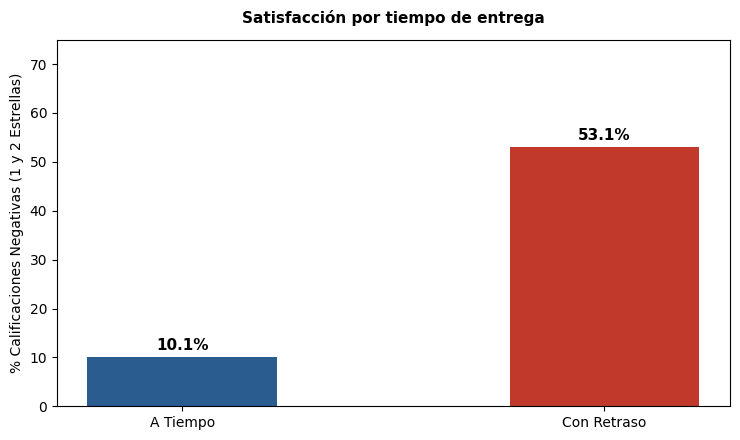

In [140]:
tasa_retraso = df.groupby('entrega_tardia', observed=False)['es_detractor'].mean() * 100
print("Porcentaje de clientes detractores según cumplimiento:")
display(tasa_retraso.round(2).astype(str) + '%')

fig, ax = plt.subplots(figsize=(7.5, 4.5))

colores = ['#2b5c8f', '#c0392b']
barras = ax.bar(tasa_retraso.index, tasa_retraso.values, color=colores, width=0.45)

for b in barras:
    altura = b.get_height()
    ax.annotate(f'{altura:.1f}%',
                xy=(b.get_x() + b.get_width() / 2, altura),
                xytext=(0, 5), textcoords="offset points",
                ha='center', fontweight='bold', fontsize=11)

ax.set_title("Satisfacción por tiempo de entrega",
             fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel("% Calificaciones Negativas (1 y 2 Estrellas)")
ax.set_ylim(0, 75)

plt.tight_layout()
plt.savefig("grafico_1_retraso.png", dpi=300)
plt.show()

En el gráfico anterior, es posible visualizar la cantidad de detractores que existen dependiendo si el paquete llegó a tiempo o no.
En este caso, se logra determinar que existe un 10,1% de detractores para aquellos paquetes que llegaron a tiempo y alrededor de un 53,1% de detractores entre aquellos cientes que recibieron su paquete tarde, lo que da a conocer un comportamiento claro, y es que por el hecho de que el paquete llegue tarde aumenta 5 veces más la cantidad de detractores, afectando la confianza del cliente hacia los e-commerce.

Porcentaje de detractores según flete o precio:


,es_detractor
rango_flete,
Bajo (<13%),13.17%
Medio-Bajo (13-20%),12.72%
Medio-Alto (20-33%),13.08%
Alto (>33%),14.27%


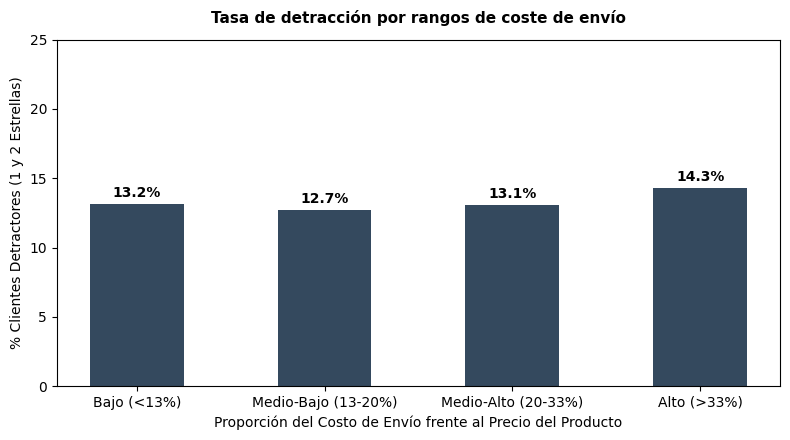

In [141]:
tasa_flete = df.groupby('rango_flete', observed=False)['es_detractor'].mean() * 100
print("Porcentaje de detractores según flete o precio:")
display(tasa_flete.round(2).astype(str) + '%')

fig, ax = plt.subplots(figsize=(8, 4.5))

barras2 = ax.bar(tasa_flete.index, tasa_flete.values, color='#34495e', width=0.5)

for b in barras2:
    altura = b.get_height()
    ax.annotate(f'{altura:.1f}%',
                xy=(b.get_x() + b.get_width() / 2, altura),
                xytext=(0, 5), textcoords="offset points",
                ha='center', fontweight='bold', fontsize=10)

ax.set_title("Tasa de detracción por rangos de coste de envío",
             fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel("% Clientes Detractores (1 y 2 Estrellas)")
ax.set_xlabel("Proporción del Costo de Envío frente al Precio del Producto")
ax.set_ylim(0, 25)

plt.tight_layout()
plt.savefig("grafico_2_flete_relativo.png", dpi=300)
plt.show()

En el gráfico anterior es posible visualizar diferentes rangos de costo de envío que va de bajo a alto y si bien la insatisfacción aumenta un poco a partir de los costos de envío superiores al 33% del precio del producto, no es un dato significativo y contundente, lo que quiere decir que el hecho de que el cliente deba pagar más por su coste de envío, no significa que vaya a estar insatisfecho automáticamente.

Porcentaje de pedidos con retraso:


,dias_desvio_promesa
customer_state,
PR,4.65%
MG,5.25%
SP,5.54%
RS,6.53%
DF,6.7%
GO,7.38%
SC,9.31%
ES,11.33%
RJ,11.93%


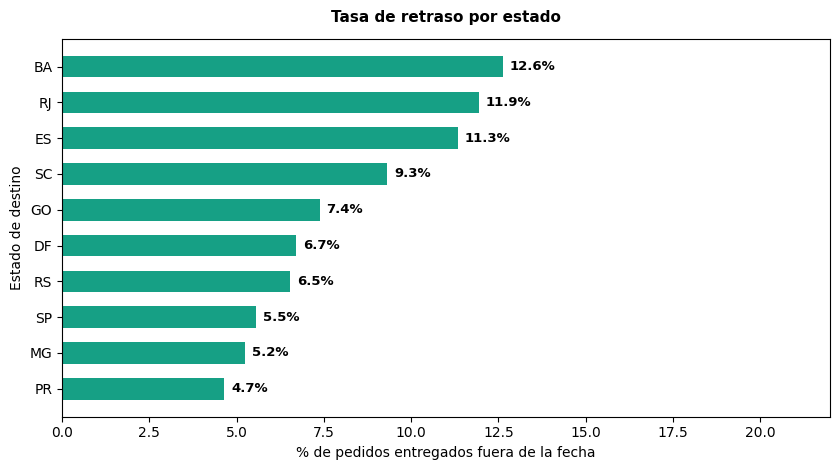

In [142]:
top_estados = df['customer_state'].value_counts().head(10).index
df_top_estados = df[df['customer_state'].isin(top_estados)]

retraso_estado = (df_top_estados.groupby('customer_state', observed=False)['dias_desvio_promesa']
                  .apply(lambda x: (x > 0).mean()) * 100).sort_values(ascending=True)

print("Porcentaje de pedidos con retraso:")
display(retraso_estado.round(2).astype(str) + '%')

fig, ax = plt.subplots(figsize=(8.5, 4.8))

barras3 = ax.barh(retraso_estado.index, retraso_estado.values, color='#16a085', height=0.6)

for b in barras3:
    ancho = b.get_width()
    ax.annotate(f'{ancho:.1f}%',
                xy=(ancho, b.get_y() + b.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                ha='left', va='center', fontweight='bold', fontsize=9.5)

ax.set_title("Tasa de retraso por estado",
             fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("% de pedidos entregados fuera de la fecha")
ax.set_ylabel("Estado de destino")
ax.set_xlim(0, 22)

plt.tight_layout()
plt.show()

En el gráfico anterior nos enfocamos en los estados de Brasil que más sufren de retrasos, siendo en este caso Bahía, Espírito Santo y Rio de Janeiro los más afetados mientras que otros estados como Paraná, Minas Gerais y Sao Paulo cuentan con menor cantidad de retraso.
Esto podría deberse a las ubicaciones de los vendedores, siendo los estados mas afectados, aquellos que se encuentran más lejos del lugar de despacho

In [143]:
top_origen = (despachos_origen['seller_state'].value_counts(normalize=True).head(5) * 100).round(2)
print("Porcentaje de despachos según el estado de origen del vendedor")
display(top_origen.astype(str) + '%')

Porcentaje de despachos según el estado de origen del vendedor


,proportion
seller_state,
SP,71.32%
MG,7.84%
PR,7.7%
RJ,4.28%
SC,3.62%


La tabla anterior confirma la sospecha;
Sao Paulo, Minas Gerais y Paraná concentran la mayor cantidad de vendedores logrando un tiempo de espera menor, mientras que los demás estados sufren por la lejanía de los mismos.

Media de días de tránsito según rango de peso:


,dias_transito_real
rango_peso,
Liviano (<1 kg),11.7 días
Medio (1-5 kg),12.5 días
Pesado (>5 kg),13.7 días


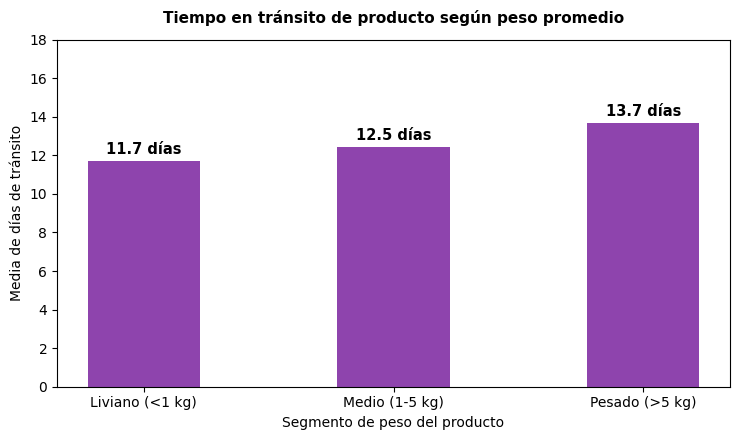

In [144]:
transito_peso = df.groupby('rango_peso', observed=False)['dias_transito_real'].mean()
print("Media de días de tránsito según rango de peso:")
display(transito_peso.round(1).astype(str) + ' días')

fig, ax = plt.subplots(figsize=(7.5, 4.5))

barras4 = ax.bar(transito_peso.index, transito_peso.values, color='#8e44ad', width=0.45)

for b in barras4:
    altura = b.get_height()
    ax.annotate(f'{altura:.1f} días',
                xy=(b.get_x() + b.get_width() / 2, altura),
                xytext=(0, 5), textcoords="offset points",
                ha='center', fontweight='bold', fontsize=10.5)

ax.set_title("Tiempo en tránsito de producto según peso promedio",
             fontsize=11, fontweight='bold', pad=12)
ax.set_ylabel("Media de días de tránsito")
ax.set_xlabel("Segmento de peso del producto")
ax.set_ylim(0, 18)

plt.tight_layout()
plt.savefig("grafico_4_peso_transito.png", dpi=300)
plt.show()

También quise indagar si el peso de un producto podía influir en los días que tardaba en llegar al usuario. Por esta razón, creé el gráfico anterior que clasifica los productos entre livianos, peso medio y pesados y usamos la media para ver cual tarda más en llegar.

En este caso, vemos que aquellos productos que son más pesados tardan más tiempo en llegar, de hecho tardan 1.9 días más los productos pesados que los livianos, por lo que una hipótesis sobre esto podría ser que el usuario al adquirir un producto que pesa más, aquel tarda más timepo en llegar y por consiguiente debilita la satisfacción del cliente.

Porcentaje de clientes detractores por categorías:


,es_detractor
product_category_name,
Beleza Saude,11.26%
Brinquedos,11.37%
Esporte Lazer,11.52%
Utilidades Domesticas,12.11%
Automotivo,12.97%
Relogios Presentes,14.11%
Telefonia,14.45%
Informatica Acessorios,14.9%
Moveis Decoracao,15.85%


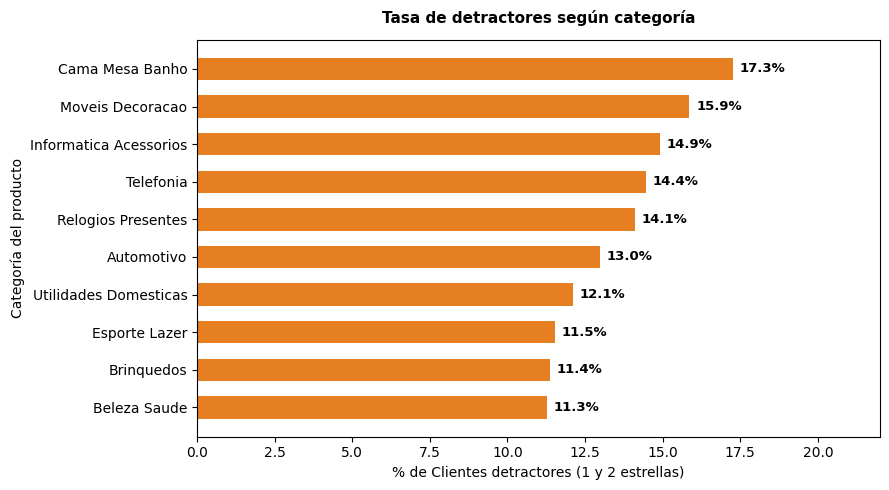

In [145]:
top_categorias = df['product_category_name'].value_counts().head(10).index
df_top_cat = df[df['product_category_name'].isin(top_categorias)]

detractor_cat = (df_top_cat.groupby('product_category_name', observed=False)['es_detractor']
                 .mean() * 100).sort_values(ascending=True)

print("Porcentaje de clientes detractores por categorías:")
display(detractor_cat.round(2).astype(str) + '%')

fig, ax = plt.subplots(figsize=(9, 5))

barras5 = ax.barh(detractor_cat.index, detractor_cat.values, color='#e67e22', height=0.6)

for b in barras5:
    ancho = b.get_width()
    ax.annotate(f'{ancho:.1f}%',
                xy=(ancho, b.get_y() + b.get_height() / 2),
                xytext=(5, 0), textcoords="offset points",
                ha='left', va='center', fontweight='bold', fontsize=9.5)

ax.set_title("Tasa de detractores según categoría",
             fontsize=11, fontweight='bold', pad=12)
ax.set_xlabel("% de Clientes detractores (1 y 2 estrellas)")
ax.set_ylabel("Categoría del producto")
ax.set_xlim(0, 22)

plt.tight_layout()
plt.savefig("grafico_5_categorias.png", dpi=300)
plt.show()

Otro hallazgo interesante a revisar son las categorías que obtienen mayor cantidad de detractores, siendo artículos para el hogar, muebles y tecnología los más afectados y belleza, juguetes y deportes los que menos.
Aquello podría deberse también darse por el tema del peso pues al ser productos más pesados, tardan más en ser enviados a sus destinos y si eso lo combinamos con que el usuario que pidió el producto vive en un estado lejos del lugar de despacho hace que la experiencia sea mucho peor y la posibilidad de que se vuelva detractor aumente.

Resumen mensual de volumen y tasa de retraso:


,periodo_mes,total_pedidos,tasa_retraso
0,2017-01,765,1.568627
1,2017-02,1691,2.128918
2,2017-03,2585,4.603482
3,2017-04,2354,7.264231
4,2017-05,3645,3.292181
5,2017-06,3208,3.397756
6,2017-07,3992,2.980962
7,2017-08,4329,3.187803
8,2017-09,4258,4.931893
9,2017-10,4634,4.898576


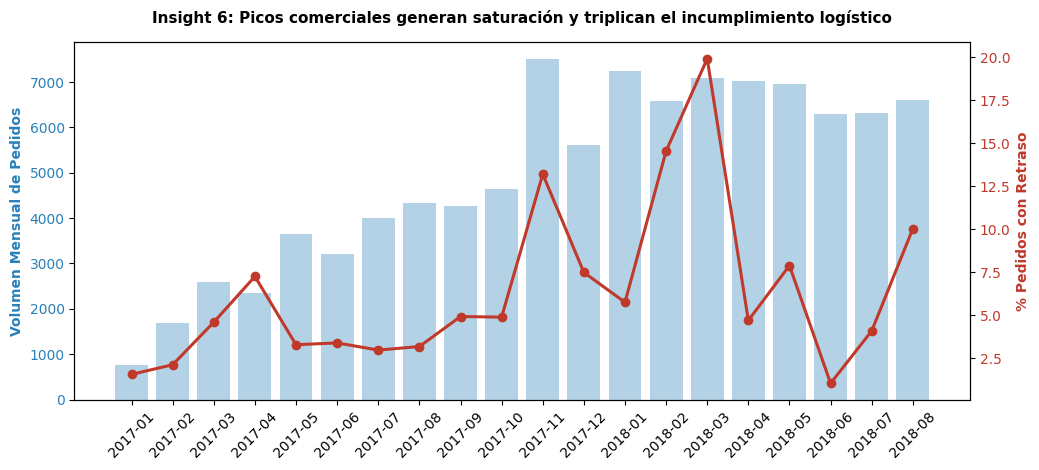

In [146]:
df['periodo_mes'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
df_tiempo = df[(df['periodo_mes'] >= '2017-01') & (df['periodo_mes'] <= '2018-08')].copy()

resumen_mes = df_tiempo.groupby('periodo_mes').agg(
    total_pedidos=('order_id', 'count'),
    tasa_retraso=('dias_desvio_promesa', lambda x: (x > 0).mean() * 100)
).reset_index()

print("Resumen mensual de volumen y tasa de retraso:")
display(resumen_mes.head(10))

fig, ax1 = plt.subplots(figsize=(10.5, 4.8))

color_pedidos = '#2980b9'
color_retrasos = '#c0392b'

ax1.bar(resumen_mes['periodo_mes'], resumen_mes['total_pedidos'],
        color=color_pedidos, alpha=0.35, label='Volumen de Pedidos')
ax1.set_ylabel("Volumen Mensual de Pedidos", color=color_pedidos, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_pedidos)
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
ax2.plot(resumen_mes['periodo_mes'], resumen_mes['tasa_retraso'],
         color=color_retrasos, marker='o', linewidth=2.2, label='% Pedidos con Retraso')
ax2.set_ylabel("% Pedidos con Retraso", color=color_retrasos, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_retrasos)
ax2.grid(False)

plt.title("Insight 6: Picos comerciales generan saturación y triplican el incumplimiento logístico",
          fontsize=11, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig("grafico_6_estacionalidad.png", dpi=300)
plt.show()

Por último, quise comparar la evolución de los pedidos mensuales con el porcentaje de pedidos con retraso con el fin de ver si los picos comerciales estaban relacionados con el retraso de entregas.
Lo que se puede determinar de este gráfico es que si bien al inicio pudo existir retraso de pedidos debido al aumento de compras, tambien hubo momentos saturados en donde los retrasos disminuyeron por lo que no se puede decir con exactitud que esa sea la principal razón por la cual se retrasan

## Conclusiones y Recomendaciones

### Conclusiones del Análisis Exploratorio
A partir de la exploración realizada sobre los 100k pedidos entregados en Olist, es posible concluir que la insatisfacción del cliente está determinada  por el cumplimiento de los tiempos de entrega y no por el costo del envío. Mientras que un costo superior al 33% del valor del producto apenas eleva levemente la tasa de detractores sin llegar a ser un factor determinante, recibir el paquete después de la fecha prometida aumenta por cinco la probabilidad de obtener una calificación negativa, pasando del 10,1% al 53,1%.

Al profundizar en las causas detrás de estas demoras, se evidencia un fuerte componente geográfico y físico. La concentración de más del 86% de los despachos en São Paulo (71,32%), Minas Gerais (7,84%) y Paraná (7,7%) permite tiempos de espera reducidos en el eje centro-sur, pero castiga a estados más alejados como Bahía, Río de Janeiro y Espírito Santo, donde los retrasos superan el 10%. A esto se suma también el impacto del peso del producto, ya que los artículos pesados tardan en promedio cerca de 2 días más en llegar que los livianos. Esta combinación explica por qué categorías como hogar (Cama Mesa Banho), muebles y tecnología lideran la cantidad de detractores pues al tratarse de productos más pesados o delicados que muchas veces viajan hacia estados distantes del punto de despacho, la experiencia de entrega se deteriora considerablemente.

Por último, al contrastar la evolución mensual de las compras contra el porcentaje de incumplimiento, se observa que si bien en algunos picos comerciales subieron las demoras, también existieron meses con alto volumen de pedidos donde los retrasos disminuyeron. Por esta razón, no se puede afirmar que la saturación por volumen mensual sea la causa principal de los retrasos, lo que refuerza la hipótesis de que el problema responde más a distancias de ruta, logística de carga pesada y tiempos prometidos poco realistas.

### Recomendaciones de Negocio
Con base en los hallazgos anteriores,

1. Hay que recalcular las fechas estimadas de entrega según la ruta dado que el retraso es el mayor detonante de detractores y que los envíos hacia estados alejados de los vendedores como Bahía o Espírito Santo enfrentan viajes mucho más largos desde São Paulo, por lo que resulta mejor mostrar al comprador un plazo de entrega ligeramente más amplio pero realista antes que incumplir la promesa.

2. Reforzar los estándares de empaque para productos pesados y categorías como hogar, muebles y tecnología. Podría ser priorizando transportistas especializados en carga pesada.

3. Incentivar a vendedores fuera de los estados como SP, MG y PR para descentralizar los despachos y acercar el inventario a las regiones con mayor tasa de demora.